In [1]:
import pandas as pd
insurance = pd.read_csv("insurance.csv")
insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
insurance.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [3]:
insurance.describe(include="all")

,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


In [4]:
missing_values = insurance.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [5]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index
print(f"Kolom aman: {less.tolist()}")
print(f"Kolom banyak hilang: {over.tolist()}")

Kolom aman: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
Kolom banyak hilang: []


In [6]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = insurance.select_dtypes(include='number').columns
insurance[numeric_features] = insurance[numeric_features].fillna(insurance[numeric_features].median())

In [7]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = insurance.select_dtypes(include='object').columns
for column in kategorical_features:
    insurance[column] = insurance[column].fillna(insurance[column].mode()[0])

C:\Users\acer\AppData\Local\Temp\ipykernel_8460\2364485399.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kategorical_features = insurance.select_dtypes(include='object').columns


In [8]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = insurance.drop(columns=over)

In [9]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

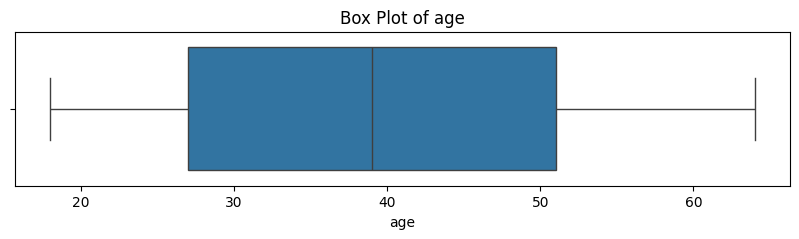

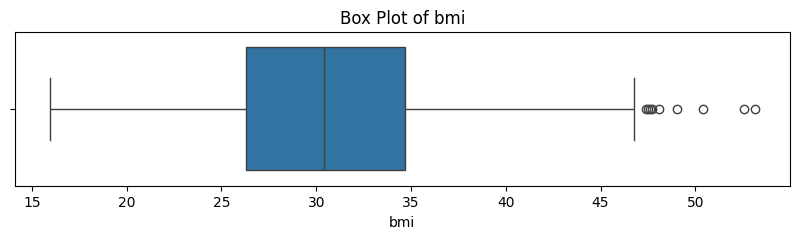

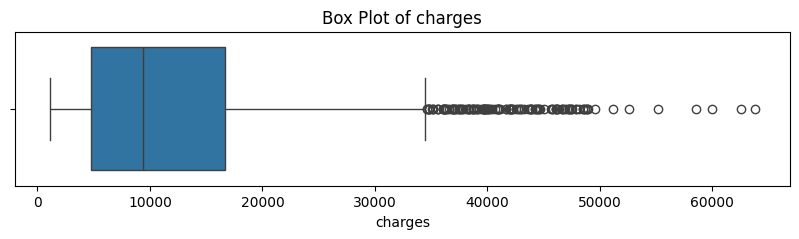

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in ['age', 'bmi', 'charges']:
    plt.figure(figsize=(10, 2))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [11]:
#contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [12]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Gabung kembali dengan kategorikal
df = pd.concat([df_filtered_numeric, df.loc[condition, kategorical_features]], axis=1)
print(f"Data sebelum filter: 1338, setelah filter outlier: {len(df)}")
df.head()

Data sebelum filter: 1338, setelah filter outlier: 1193


,age,bmi,children,charges,sex,smoker,region
0,19,27.900,0,16884.92400,female,yes,southwest
1,18,33.770,1,1725.55230,male,no,southeast
2,28,33.000,3,4449.46200,male,no,southeast
3,33,22.705,0,21984.47061,male,no,northwest
4,32,28.880,0,3866.85520,male,no,northwest


In [13]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])
print("Setelah StandardScaler:")
print(df.head())

Setelah StandardScaler:
        age       bmi  children   charges     sex smoker     region
0 -1.421407 -0.357841 -0.892872  0.957834  female    yes  southwest
1 -1.492543  0.643111 -0.070327 -1.133608    male     no  southeast
2 -0.781184  0.511811  1.574764 -0.757808    male     no  southeast
3 -0.425504 -1.243693 -0.892872  1.661386    male     no  northwest
4 -0.496640 -0.190732 -0.892872 -0.838186    male     no  northwest


In [14]:
#Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
          age       bmi  children   charges   sex smoker     region
581 -1.421407  0.100858 -0.892872 -1.145472  male     no  northwest


In [15]:
#Menghapus Baris duplikat
df = df.drop_duplicates()

#cek ukuran dataframe setelah duplikatt dihapus
df.shape

(1192, 7)

In [16]:
duplicates = df.duplicated()
print('Jumlah baris duplikat:', duplicates.sum())


Jumlah baris duplikat: 0


In [17]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print(f'Data setelah hapus duplikat: {len(df)} baris')

Data setelah hapus duplikat: 1192 baris


In [18]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

C:\Users\acer\AppData\Local\Temp\ipykernel_8460\2319133481.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,sex,smoker,region
0,female,yes,southwest
1,male,no,southeast
2,male,no,southeast
3,male,no,northwest
4,male,no,northwest
...,...,...,...
1333,male,no,northwest
1334,female,no,northeast
1335,female,no,southeast
1336,female,no,southwest


In [19]:
# One Hot Encoding
df_one_hot = pd.get_dummies(df, columns=category_features)
print(df_one_hot.head())

        age       bmi  children   charges  sex_female  sex_male  smoker_no  \
0 -1.421407 -0.357841 -0.892872  0.957834        True     False      False   
1 -1.492543  0.643111 -0.070327 -1.133608       False      True       True   
2 -0.781184  0.511811  1.574764 -0.757808       False      True       True   
3 -0.425504 -1.243693 -0.892872  1.661386       False      True       True   
4 -0.496640 -0.190732 -0.892872 -0.838186       False      True       True   

   smoker_yes  region_northeast  region_northwest  region_southeast  \
0        True             False             False             False   
1       False             False             False              True   
2       False             False             False              True   
3       False             False              True             False   
4       False             False              True             False   

   region_southwest  
0              True  
1             False  
2             False  
3             Fa

In [20]:
from sklearn.preprocessing import LabelEncoder

#Inisialisasi LabelEncoder

label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

#menampilkan hasil
df_lencoder

,age,bmi,children,charges,sex,smoker,region
0,-1.421407,-0.357841,-0.892872,0.957834,0,1,3
1,-1.492543,0.643111,-0.070327,-1.133608,1,0,2
2,-0.781184,0.511811,1.574764,-0.757808,1,0,2
3,-0.425504,-1.243693,-0.892872,1.661386,1,0,1
4,-0.496640,-0.190732,-0.892872,-0.838186,1,0,1
...,...,...,...,...,...,...,...
1333,0.783807,0.165655,1.574764,0.090819,1,0,1
1334,-1.492543,0.327649,-0.892872,-1.067327,0,0,0
1335,-1.492543,1.168313,-0.892872,-1.146814,0,0,2
1336,-1.279136,-0.715933,-0.892872,-1.094648,0,0,3


In [21]:
df_lencoder.head()

,age,bmi,children,charges,sex,smoker,region
0,-1.421407,-0.357841,-0.892872,0.957834,0,1,3
1,-1.492543,0.643111,-0.070327,-1.133608,1,0,2
2,-0.781184,0.511811,1.574764,-0.757808,1,0,2
3,-0.425504,-1.243693,-0.892872,1.661386,1,0,1
4,-0.496640,-0.190732,-0.892872,-0.838186,1,0,1


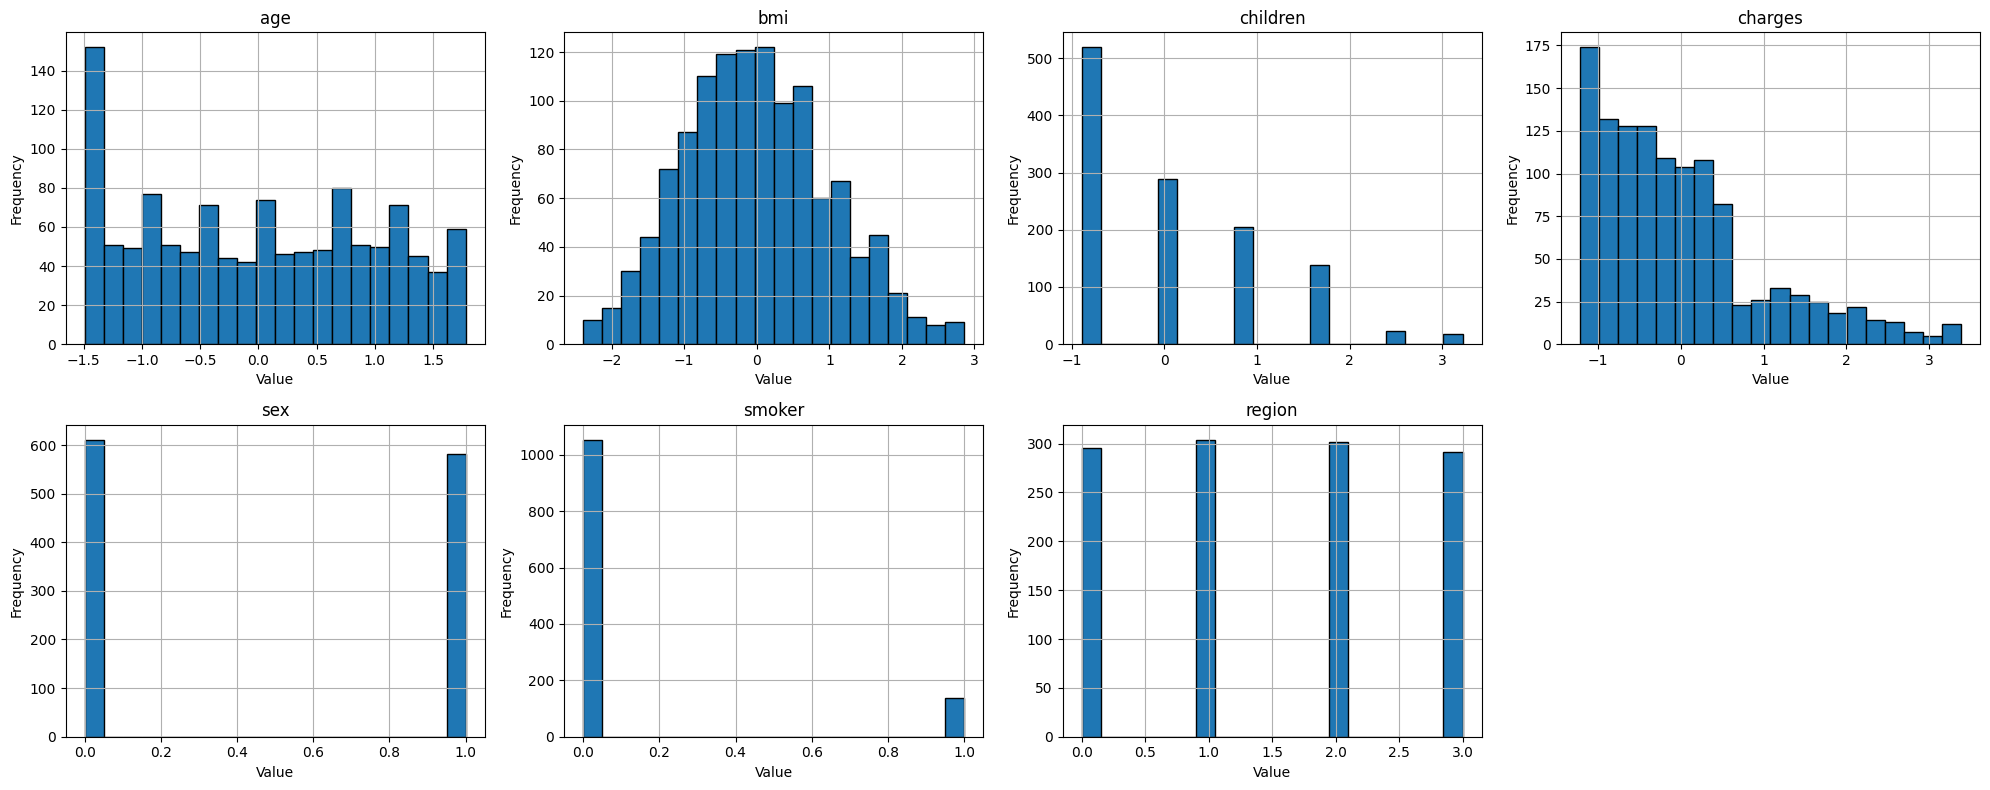

In [22]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]
# Menentukan grid subplot
n_cols = 4
n_rows = -(-num_vars // n_cols) # Ceiling division
# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
# Flatten
axes = axes.flatten()
# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
# Hapus subplot yang tidak terpakai
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
# Layout
plt.tight_layout()
plt.show()

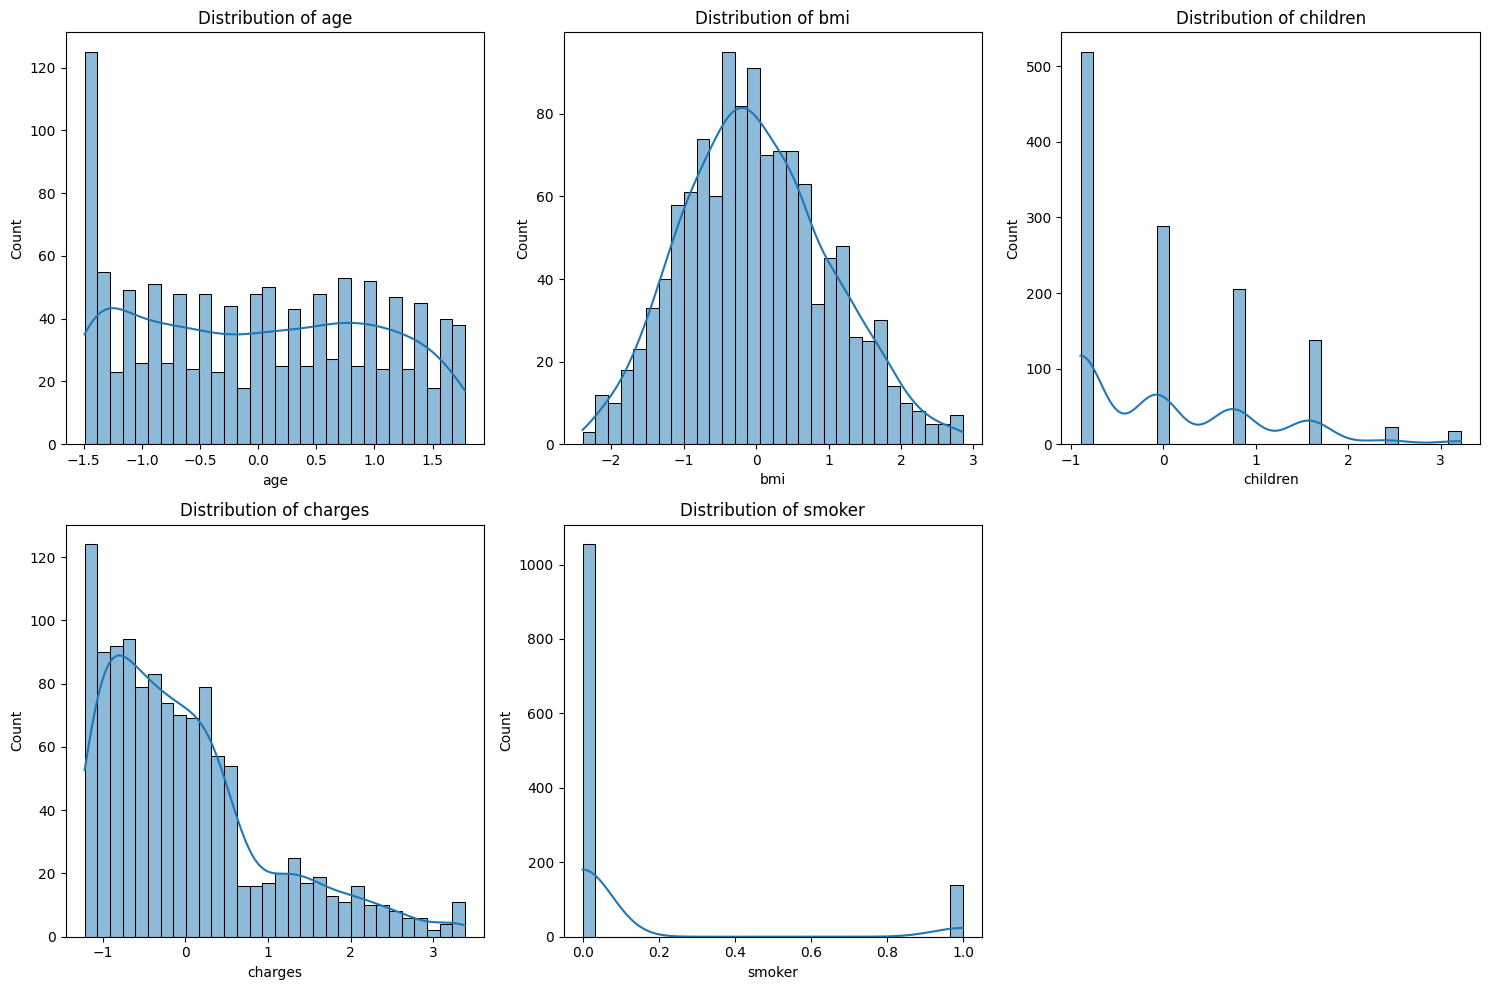

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom Medical Insurance
columns_to_plot = ['age', 'bmi', 'children', 'charges', 'smoker']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

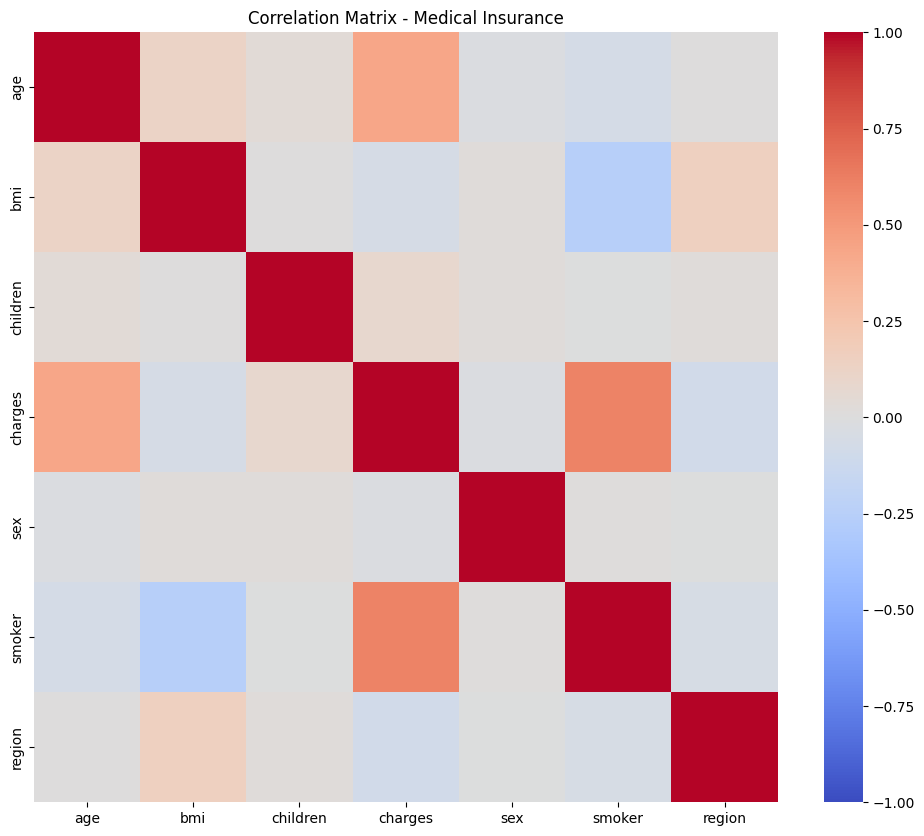

In [24]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix - Medical Insurance')
plt.show()

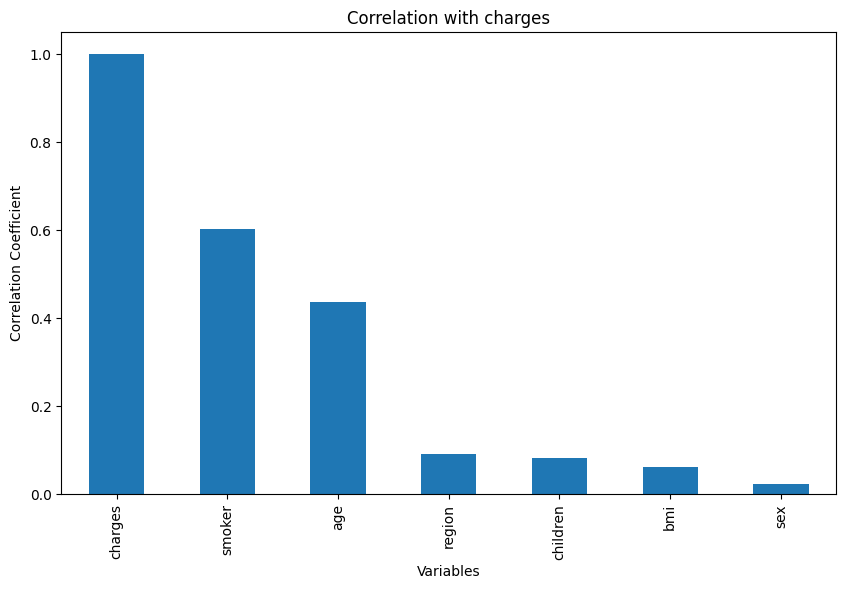

charges     1.000000
smoker      0.602377
age         0.436059
region      0.090858
children    0.082308
bmi         0.060969
sex         0.021548
Name: charges, dtype: float64


In [25]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['charges']

# (Opsional) Mengurutkan hasil korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with charges')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

print(target_corr_sorted)

In [26]:
# Import library SKLearn
import sklearn
from sklearn.model_selection import train_test_split

In [27]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns='charges')
y = df_lencoder['charges']

print("X shape (fitur):", X.shape)
print("y shape (target):", y.shape)
print("\nKolom X:", X.columns.tolist())

X shape (fitur): (1192, 6)
y shape (target): (1192,)

Kolom X: ['age', 'bmi', 'children', 'sex', 'smoker', 'region']


In [28]:
# 3. Membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [29]:
#menghitung panjang/jumlah data
print("Jumlah data: ",len(X))
#menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(X_train))
#menghitung panjang/jumlah data padax_test
print("Jumlah data test: ",len(X_test))

Jumlah data:  1192
Jumlah data latih:  953
Jumlah data test:  239


In [30]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1)
lars.fit(X_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression()
LR.fit(X_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(X_train, y_train)

print("3 Model berhasil dilatih dengan Medical Insurance")

3 Model berhasil dilatih dengan Medical Insurance


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(X_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,0.739069,0.935272,0.156653


In [32]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(X_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.739069,0.935272,0.156653
Linear Regression,0.379773,0.442037,0.601409


In [33]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(X_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.739069,0.935272,0.156653
Linear Regression,0.379773,0.442037,0.601409
GradientBoostingRegressor,0.332327,0.394570,0.644211


In [34]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model_medical_insurance.joblib')
print("Model disimpan sebagai gbr_model_medical_insurance.joblib")

Model disimpan sebagai gbr_model_medical_insurance.joblib


In [35]:
#membuat model dari file joblib
joblib_model = joblib.load('gbr_model_medical_insurance.joblib')

In [36]:
from flask import Flask, request, jsonify
import joblib

# Inisialisasi aplikasi Flask
app = Flask(__name__)

# Memuat model yang telah disimpan
joblib_model = joblib.load('gbr_model_medical_insurance.joblib')

@app.route('/predict', methods=['POST'])
def predict():
    data = request.json['data']  # Mengambil data dari request JSON
    prediction = joblib_model.predict(data)  # Melakukan prediksi
    return jsonify({'prediction': prediction.tolist()})

if __name__ == '__main__':
    app.run(debug=True)

 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
 * Restarting with stat


SystemExit: 1

C:\Users\acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\interactiveshell.py:3755: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [37]:
import joblib
import numpy as np

# load model yang udah kamu train
joblib_model = joblib.load('gbr_model_medical_insurance.joblib')

# test prediksi langsung di Jupyter
data = [[19, 0, 27.9, 0, 1, 0]]
hasil = joblib_model.predict(data)
print(hasil)

[2.77634046]


C:\Users\acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(
